In [1]:
# Core libraries used throughout the time-series exercises.
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The project-specific forecast interval helper is kept in utils.py.
import utils as ad

# Time-Series Exploration and Forecasting

This notebook studies monthly incident counts with additive seasonal decomposition, simple and seasonal exponential smoothing, ARMA/ARIMA forecasting, autocorrelation diagnostics, and chronological regression validation. A separate **optional rainfall exercise** illustrates moving averages and simple exponential smoothing.

**Dataset chronology.** The 118 incident values correspond to **January 1966–October 1975**. This was cross-checked against `data/annual_incident_matrix.csv`: its final two zero entries are padding, not observations. We retain the original numerical observations and model order/smoothing settings.

**Optional input.** `data/LondonRainfall.txt` was not supplied in this archive. Rainfall cells skip cleanly unless that original file is restored; no replacement observations are generated.

**Execution.** Run from this project folder so the relative `data/` paths and `utils.py` resolve. The notebook has not been re-executed as part of the repair, and stored outputs have been cleared to avoid displaying stale results.

In [2]:
# Load the original monthly series; the values and column name are unchanged.
crime = pd.read_csv('data/monthly_incident_counts.csv')
print(f"Monthly observations: {len(crime)}")
crime.info()
display(crime.head())

Monthly observations: 118
<class 'pandas.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 1 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   f03_observed_value  118 non-null    int64
dtypes: int64(1)
memory usage: 1.1 KB


,f03_observed_value
0,41
1,39
2,50
3,40
4,43


In [3]:
# Date labels come from the companion annual matrix, not an assumed 2000 start.
# The 118 supplied values cover January 1966 through October 1975.
crime['year_month'] = pd.date_range(
    start='1966-01-01',
    periods=len(crime),
    freq='ME',                 # Pandas 3-compatible month-end frequency.
)

assert len(crime) == 118, 'Expected 118 monthly observations in the supplied dataset.'
display(crime[['year_month', 'f03_observed_value']].head())
display(crime[['year_month', 'f03_observed_value']].tail())

,year_month,f03_observed_value
0,1966-01-31,41
1,1966-02-28,39
2,1966-03-31,50
3,1966-04-30,40
4,1966-05-31,43


,year_month,f03_observed_value
113,1975-06-30,316
114,1975-07-31,398
115,1975-08-31,394
116,1975-09-30,431
117,1975-10-31,431


In [4]:
# Give the series a proper monthly DatetimeIndex for forecasting models.
crime = crime.set_index('year_month')
crime.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 118 entries, 1966-01-31 to 1975-10-31
Data columns (total 1 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   f03_observed_value  118 non-null    int64
dtypes: int64(1)
memory usage: 1.8 KB


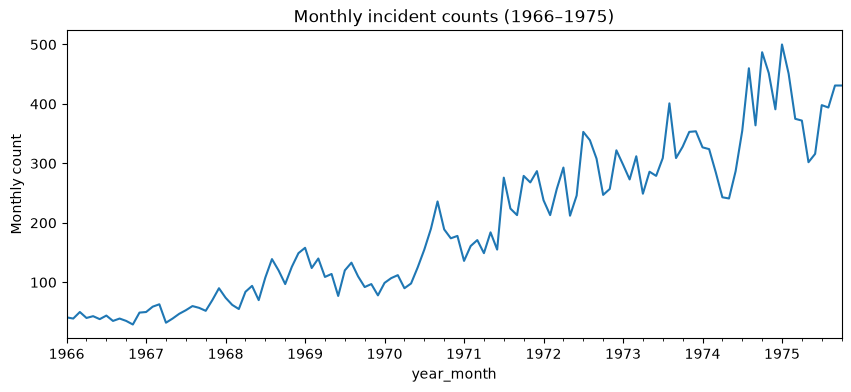

In [5]:
# Inspect the original monthly counts before fitting any models.
crime['f03_observed_value'].plot(title='Monthly incident counts (1966–1975)', figsize=(10, 4))
plt.ylabel('Monthly count')
plt.show()

## 2. Trend, seasonal pattern and residuals

Use the classical **additive** seasonal decomposition to separate the observed series into trend, seasonal and residual components. With a monthly `DatetimeIndex`, the yearly periodicity is expressed by `period=12`. Edge observations in the estimated trend/residual can be missing because the centered moving average needs neighbors on both sides.

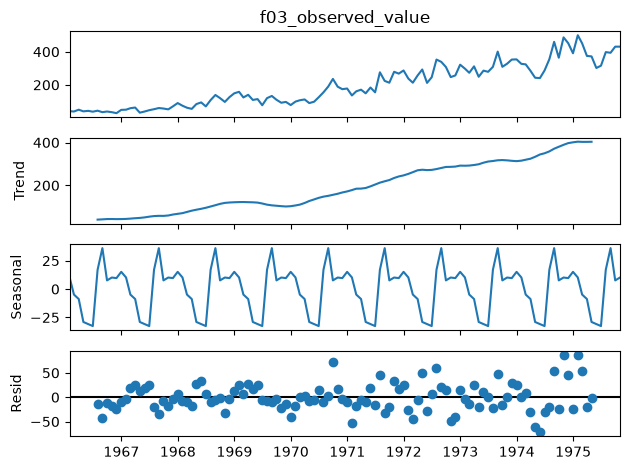

In [6]:
# Decompose the 118 monthly values into additive components.
from statsmodels.tsa.seasonal import seasonal_decompose

crime_decomposed = seasonal_decompose(
    crime['f03_observed_value'], model='additive', period=12
)
crime_decomposed.plot()
plt.show()

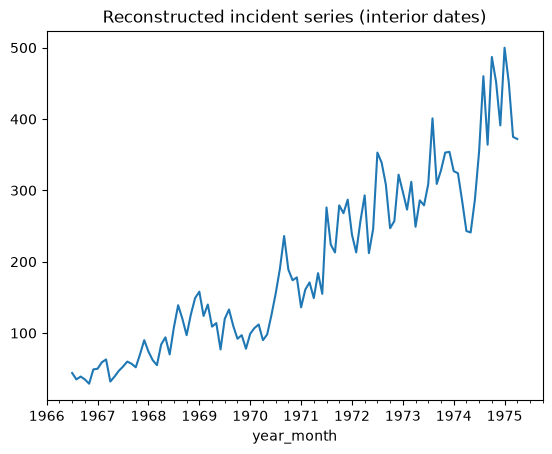

In [7]:
# Reconstruction agrees with the original data wherever all components exist.
reconstructed = (
    crime_decomposed.trend
    + crime_decomposed.seasonal
    + crime_decomposed.resid
)
reconstructed.plot(title='Reconstructed incident series (interior dates)')
plt.show()

## 3. Moving averages and exponential smoothing: optional rainfall study

The course exercise requires **`data/LondonRainfall.txt`**, which is not included in this package. When the file is available, the cells below read its whitespace-separated numeric observations (after the original first-line skip), construct an annual index starting in 1813, and reproduce the original SMA, WMA and SES experiments.

When it is missing, the rainfall cells display one informative message and skip without interrupting the monthly incident forecasting exercises. Supplying an unrelated rainfall dataset would alter the study's results, so none is substituted.

In [8]:
# Locate the optional rainfall source. Do not overwrite crime or its date index.
rain_path = Path('data/LondonRainfall.txt')
rain = None
rain_source = None

if rain_path.is_file():
    rain_source = pd.read_csv(rain_path, header=None, skiprows=1, dtype=str)
    print(f'Loaded rainfall data from {rain_path}')
    display(rain_source.head())
else:
    print(f'Rainfall file not found: {rain_path}. Skipping optional rainfall exercises.')

Rainfall file not found: data/LondonRainfall.txt. Skipping optional rainfall exercises.


In [9]:
# Convert the original text layout to one numeric token per observation.
# Whitespace splitting also handles irregular spacing between measurements.
if rain_source is not None:
    rainfall_tokens = ' '.join(rain_source.stack().astype(str).tolist()).split()
    print(f'Rainfall observations parsed: {len(rainfall_tokens)}')

In [10]:
# Retain the course's annual start date; use the current YE frequency alias.
if rain_source is not None:
    rain = pd.DataFrame({
        'f03_observed_value': pd.to_numeric(rainfall_tokens, errors='raise')
    })
    rain['year'] = pd.date_range(start='1813-01-01', periods=len(rain), freq='YE')
    rain = rain.set_index('year')
    rain.info()

In [11]:
if rain is not None:
    # Visualize the source observations without smoothing.
    rain['f03_observed_value'].plot(title='Historical annual rainfall')
    plt.show()

In [12]:
if rain is not None:
    # Ordinary trailing means over three and seven annual observations.
    rain['SMA3'] = rain['f03_observed_value'].rolling(window=3).mean()
    rain['SMA7'] = rain['f03_observed_value'].rolling(window=7).mean()
    rain.plot(title='Rainfall: observations, SMA3 and SMA7')
    plt.show()

In [13]:
if rain is not None:
    # Center-weighted, three-observation moving average; weights sum to one.
    weights = np.array([0.25, 0.5, 0.25])
    rain['WMA3'] = rain['f03_observed_value'].rolling(window=3).apply(
        lambda window: np.sum(weights * window), raw=True
    )
    rain[['SMA3', 'WMA3']].plot(title='Rainfall: SMA3 versus WMA3')
    plt.show()

In [14]:
if rain is not None:
    # Single exponential smoothing with its smoothing level optimized by the model.
    from statsmodels.tsa.holtwinters import SimpleExpSmoothing

    sema_model = SimpleExpSmoothing(
        rain['f03_observed_value']
    ).fit(smoothing_level=None)
    print('Estimated smoothing level:', sema_model.params['smoothing_level'])

In [15]:
if rain is not None:
    # Compare observations with the one-step fitted values from the optimized model.
    rain['SEMA'] = sema_model.fittedvalues
    rain[['f03_observed_value', 'SEMA']].plot(title='Rainfall: observed versus SES')
    plt.show()

In [16]:
if rain is not None:
    # The comparison model fixes alpha=0.3 rather than estimating it.
    sema_model_custom = SimpleExpSmoothing(
        rain['f03_observed_value']
    ).fit(smoothing_level=0.3, optimized=False)
    rain['SEMA_custom'] = sema_model_custom.fittedvalues
    rain[['f03_observed_value', 'SEMA', 'SEMA_custom']].plot(
        title='Rainfall: optimized SES and fixed alpha=0.3'
    )
    plt.show()

In [17]:
if rain is not None:
    # Five future annual values and approximate 80% intervals.
    # The shared utils.py helper uses the fitted residual standard deviation.
    rain_forecasts = ad.summarize_forecast_intervals(
        5, sema_model, rain['f03_observed_value'], confidence=0.80
    )
    display(rain_forecasts)

In [18]:
if rain is not None:
    # Use ordinal x positions to show the original series and 5 forecast points.
    original_time = np.arange(len(rain))
    forecast_time = np.arange(len(rain), len(rain) + 5)

    plt.figure(figsize=(10, 5))
    plt.plot(original_time, rain['f03_observed_value'],
             label='Observed rainfall', marker='o')
    plt.plot(forecast_time, rain_forecasts['Forecast'],
             label='SES forecast', marker='x', linestyle='dashed')
    plt.axvline(x=len(rain)-1, color='gray', linestyle='dotted')
    plt.xlabel('Time (annual observations)')
    plt.ylabel('Rainfall')
    plt.title('Five-step simple exponential smoothing forecast')
    plt.legend()
    plt.show()

In [19]:
if rain is not None:
    # Repeat the interval calculation at its default confidence of 95%.
    ad.summarize_forecast_intervals(5, sema_model, rain['f03_observed_value'])

## 4. Seasonal exponential smoothing of monthly incidents

Fit the same **additive trend + additive seasonality** model with 12-month seasonality. The monthly date index already defines its frequency, so supplying the retired `freq='M'` argument is unnecessary. Retain the original smoothing parameter estimation and the five-step forecast.

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


0.5134008137207479 0.0 0.0


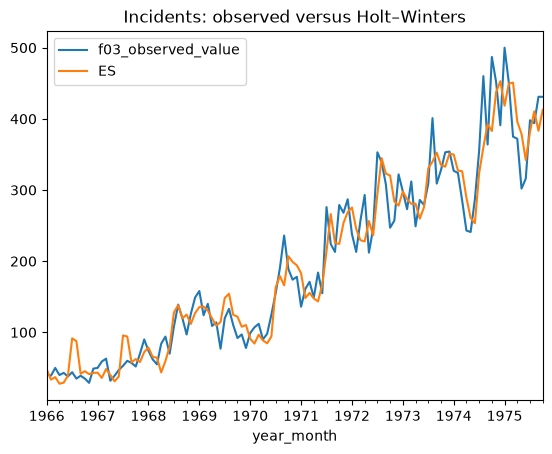

In [20]:
# Holt–Winters smoothing for monthly incident counts.
from statsmodels.tsa.holtwinters import ExponentialSmoothing

es_model = ExponentialSmoothing(
    crime['f03_observed_value'],
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated',
).fit()
print(es_model.params['smoothing_level'],
      es_model.params['smoothing_trend'],
      es_model.params['smoothing_seasonal'])
crime['ES'] = es_model.fittedvalues
crime[['f03_observed_value', 'ES']].plot(title='Incidents: observed versus Holt–Winters')
plt.show()

In [21]:
# Approximate 80% intervals around the next five monthly predictions.
incident_forecasts = ad.summarize_forecast_intervals(
    5, es_model, crime['f03_observed_value'], confidence=0.80
)
display(incident_forecasts)

,Forecast,Lower Bound,Upper Bound
1975-11-30,423.375241,380.795040,465.955442
1975-12-31,431.376839,388.796638,473.957040
1976-01-31,428.609860,386.029659,471.190061
1976-02-29,417.808038,375.227837,460.388239
1976-03-31,418.506579,375.926378,461.086779


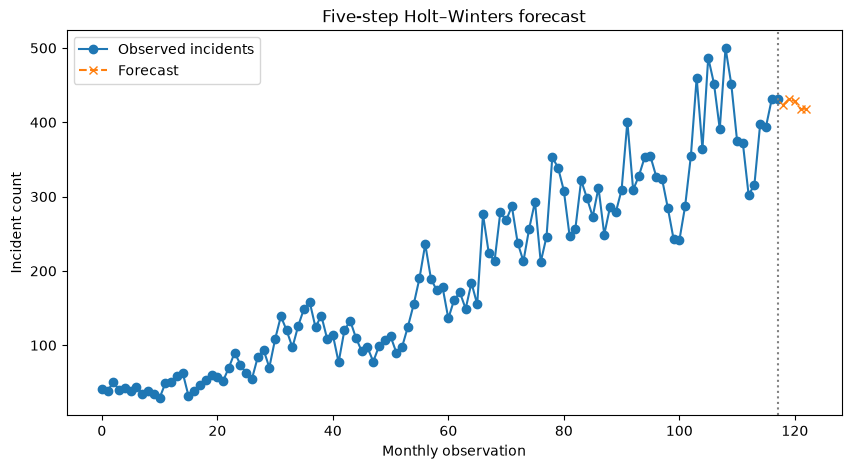

In [22]:
# Plot the incident history and the same five-step forecast.
original_time = np.arange(len(crime))
forecast_time = np.arange(len(crime), len(crime) + 5)
plt.figure(figsize=(10, 5))
plt.plot(original_time, crime['f03_observed_value'],
         label='Observed incidents', marker='o')
plt.plot(forecast_time, incident_forecasts['Forecast'],
         label='Forecast', marker='x', linestyle='dashed')
plt.axvline(x=len(crime)-1, color='gray', linestyle='dotted')
plt.xlabel('Monthly observation')
plt.ylabel('Incident count')
plt.title('Five-step Holt–Winters forecast')
plt.legend()
plt.show()

## 5. Seasonal smoothing on a chronological holdout

The last **seven monthly observations** are held out, leaving the first 111 to estimate model parameters. Compare an automatically optimized model with the same model family using a prescribed trend smoothing value of `0.5`. This is a genuine out-of-sample comparison; the earlier in-sample fit is not used for testing.

In [23]:
# Fixed chronological split: the first 111 points train, the last 7 test.
train_crime = crime['f03_observed_value'].iloc[:111]
test_crime = crime['f03_observed_value'].iloc[111:]
print('Training months:', len(train_crime), 'Testing months:', len(test_crime))

Training months: 111 Testing months: 7


In [24]:
# Fit additive trend and seasonality, estimating all smoothing parameters.
model1 = ExponentialSmoothing(
    train_crime, trend='additive', seasonal='additive', seasonal_periods=12
).fit()
predictions1 = model1.forecast(len(test_crime)).rename(
    'estimated smoothing parameters predictions'
)
results = pd.concat([test_crime, predictions1], axis=1)
display(results)

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


,f03_observed_value,estimated smoothing parameters predictions
1975-04-30,372,402.414663
1975-05-31,302,404.865955
1975-06-30,316,406.309830
1975-07-31,398,456.201616
1975-08-31,394,479.302027
1975-09-30,431,454.297287
1975-10-31,431,459.849817


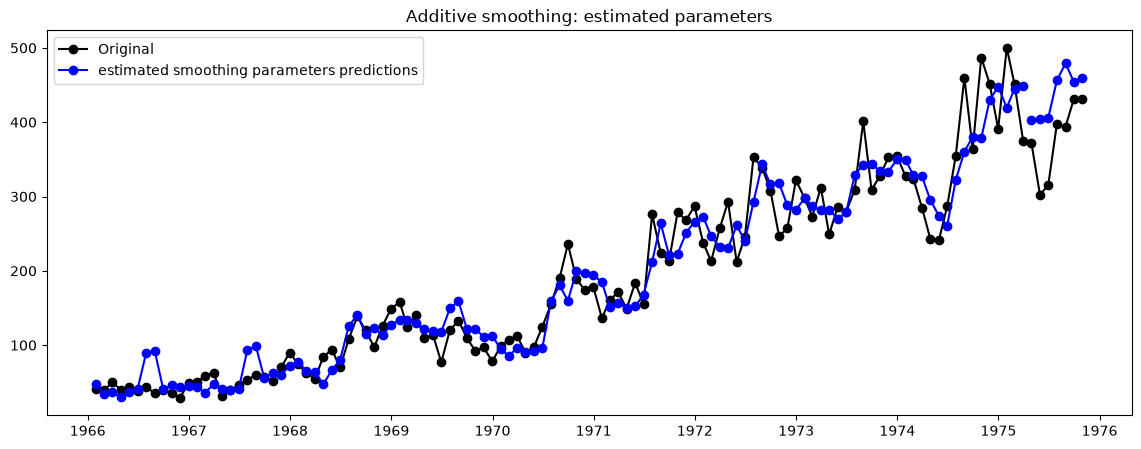

In [25]:
# Overlay training values, seven held-out observations and model-1 predictions.
plt.figure(figsize=(14, 5))
plt.plot(train_crime, marker='o', color='black')
(line0,) = plt.plot(test_crime, marker='o', color='black')
plt.plot(model1.fittedvalues, marker='o', color='blue')
(line1,) = plt.plot(predictions1, marker='o', color='blue')
plt.legend([line0, line1], ['Original', predictions1.name])
plt.title('Additive smoothing: estimated parameters')
plt.show()

In [26]:
# Report the forecast errors on the seven held-out observations.
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae1 = mean_absolute_error(test_crime, predictions1)
rmse1 = math.sqrt(mean_squared_error(test_crime, predictions1))
print(f'MAE: {mae1:.4f}')
print(f'RMSE: {rmse1:.4f}')

MAE: 59.8916
RMSE: 67.2960


In [27]:
# Keep the alternative model's original trend smoothing value (beta=0.5).
model2 = ExponentialSmoothing(
    train_crime, trend='additive', seasonal='additive', seasonal_periods=12
).fit(smoothing_trend=0.5)
predictions2 = model2.forecast(len(test_crime)).rename('beta = 0.5 predictions')
results = pd.concat([results, predictions2], axis=1)
display(results)

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


,f03_observed_value,estimated smoothing parameters predictions,beta = 0.5 predictions
1975-04-30,372,402.414663,396.300843
1975-05-31,302,404.865955,381.193951
1975-06-30,316,406.309830,365.273786
1975-07-31,398,456.201616,397.993753
1975-08-31,394,479.302027,404.112617
1975-09-30,431,454.297287,362.337159
1975-10-31,431,459.849817,351.298009


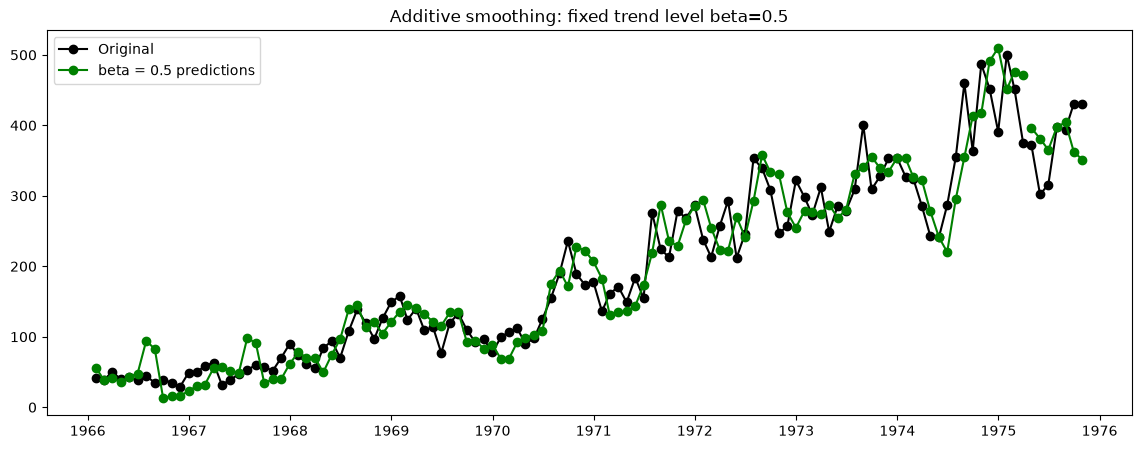

In [28]:
# Inspect the held-out fit of the fixed-trend-smoothing alternative.
plt.figure(figsize=(14, 5))
plt.plot(train_crime, marker='o', color='black')
(line0,) = plt.plot(test_crime, marker='o', color='black')
plt.plot(model2.fittedvalues, marker='o', color='green')
(line2,) = plt.plot(predictions2, marker='o', color='green')
plt.legend([line0, line2], ['Original', predictions2.name])
plt.title('Additive smoothing: fixed trend level beta=0.5')
plt.show()

In [29]:
# Compute identical error metrics for a like-for-like comparison.
mae2 = mean_absolute_error(test_crime, predictions2)
rmse2 = math.sqrt(mean_squared_error(test_crime, predictions2))
print(f'MAE: {mae2:.4f}')
print(f'RMSE: {rmse2:.4f}')

MAE: 44.4646
RMSE: 54.0626


## 6. Autocorrelation diagnostics

ACF helps visualize persistence and potential seasonality. The long-lag chart (117 lags from 118 data points) is included for continuity with the original tutorial but becomes statistically unstable near the available history's limit.

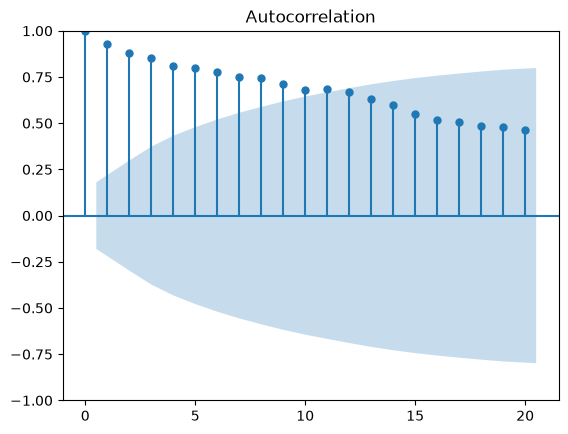

In [30]:
# Short-lag autocorrelation of the original monthly series.
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(crime['f03_observed_value'], lags=20)
plt.show()

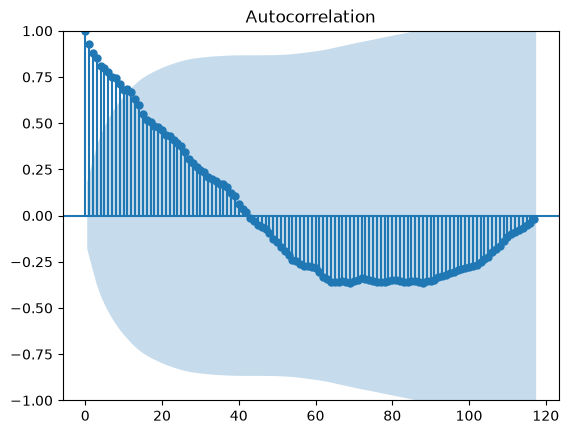

In [31]:
# Original long-lag diagnostic: interpret the final lags cautiously.
plot_acf(crime['f03_observed_value'], lags=117)
plt.show()

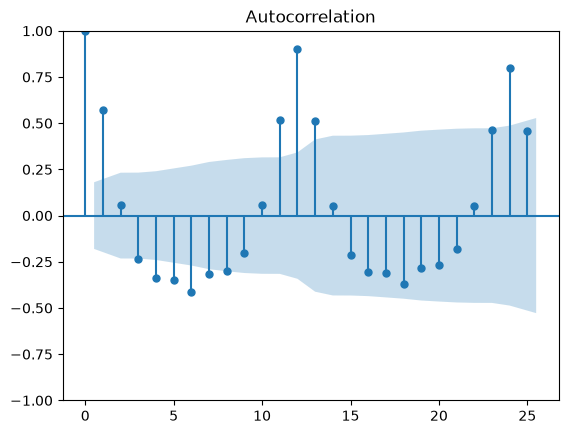

In [32]:
# Seasonal decomposition component may reveal periodic correlation.
plot_acf(crime_decomposed.seasonal.dropna(), lags=25)
plt.show()

## 7. ARMA and ARIMA

Fit the original autoregressive/moving-average model orders **(2,0,3)**, **(1,1,2)** and **(1,2,2)** to the same 111-month training subset. Forecast the following seven dates and compare the predictions to the untouched seven-month holdout.

In [33]:
# ARIMA(p,0,q) corresponds to an ARMA-style model without differencing.
from statsmodels.tsa.arima.model import ARIMA

arma_model = ARIMA(train_crime, order=(2, 0, 3)).fit()
arma_model.summary()

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:     f03_observed_value   No. Observations:                  111
Model:                 ARIMA(2, 0, 3)   Log Likelihood                -561.922
Date:                Thu, 05 Nov 2026   AIC                           1137.844
Time:                        12:18:48   BIC                           1156.810
Sample:                    01-31-1966   HQIC                          1145.538
                         - 03-31-1975                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        184.8731    153.467      1.205      0.228    -115.917     485.664
ar.L1          0.5230      0.505      1.035      0.301      -0.468       1.514
ar.L2          0.4610      0.491      0.939      0.348      -0.502       1.424
ma.L1          0.1501      0.501      0.300      0.764      -0.831       1.131
ma.L2         -0.3318      0.143     -2.324      0.020      -0.612      -0.052
ma.L3          0.0672      0.129      0.519      0.603      -0.186       0.321
sigma2      1420.8178    155.170      9.157      0.000    1116.691    1724.945
===================================================================================
Ljung-Box (L1) (Q):                   0.08   Jarque-Bera (JB):                46.35
Prob(Q):                              0.78   Prob(JB):                         0.00
Heteroskedasticity (H):              11.26   Skew:                             1.11
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.26
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [34]:
# Position-based forecast coordinates mirror the original seven-month test.
arma_preds = arma_model.predict(start=111, end=117)
arma_rmse = math.sqrt(mean_squared_error(test_crime, arma_preds))
arma_mae = mean_absolute_error(test_crime, arma_preds)
print(arma_preds)
print(f'RMSE = {arma_rmse:.2f}')
print(f'MAE: {arma_mae:.4f}')

1975-04-30    405.995790
1975-05-31    409.351143
1975-06-30    399.752290
1975-07-31    400.733730
1975-08-31    396.822062
1975-09-30    395.228740
1975-10-31    392.592224
Freq: ME, Name: predicted_mean, dtype: float64
RMSE = 56.65
MAE: 43.5477


In [35]:
# One round of differencing, with the original AR/MA orders.
arima1_model = ARIMA(train_crime, order=(1, 1, 2)).fit()
print(arima1_model.summary())
arima1_preds = arima1_model.predict(start=111, end=117)
arima1_rmse = math.sqrt(mean_squared_error(test_crime, arima1_preds))
arima1_mae = mean_absolute_error(test_crime, arima1_preds)
print(arima1_preds)
print(f'MAE: {arima1_mae:.4f}')
print(f'RMSE = {arima1_rmse:.2f}')

                               SARIMAX Results                                
Dep. Variable:     f03_observed_value   No. Observations:                  111
Model:                 ARIMA(1, 1, 2)   Log Likelihood                -555.659
Date:                Thu, 05 Nov 2026   AIC                           1119.318
Time:                        12:18:49   BIC                           1130.120
Sample:                    01-31-1966   HQIC                          1123.699
                         - 03-31-1975                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5470      0.222     -2.464      0.014      -0.982      -0.112
ma.L1          0.2211      0.225      0.980      0.327      -0.221       0.663
ma.L2         -0.3922      0.094     -4.194      0.0

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertib

In [36]:
# Compare a second-order differenced model against the same holdout.
arima2_model = ARIMA(train_crime, order=(1, 2, 2)).fit()
print(arima2_model.summary())
arima2_preds = arima2_model.predict(start=111, end=117)
arima2_rmse = math.sqrt(mean_squared_error(test_crime, arima2_preds))
arima2_mae = mean_absolute_error(test_crime, arima2_preds)
print(arima2_preds)
print(f'MAE: {arima2_mae:.4f}')
print(f'RMSE = {arima2_rmse:.2f}')

                               SARIMAX Results                                
Dep. Variable:     f03_observed_value   No. Observations:                  111
Model:                 ARIMA(1, 2, 2)   Log Likelihood                -561.890
Date:                Thu, 05 Nov 2026   AIC                           1131.779
Time:                        12:18:50   BIC                           1142.545
Sample:                    01-31-1966   HQIC                          1136.145
                         - 03-31-1975                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9854      0.075    -13.178      0.000      -1.132      -0.839
ma.L1         -0.0002      1.033     -0.000      1.000      -2.025       2.024
ma.L2         -0.9979      0.957     -1.043      0.2

/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/home/mouelhis/Work/huawei/cloud_reliability_lab/outputs/jupyter/local_notebook/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertib

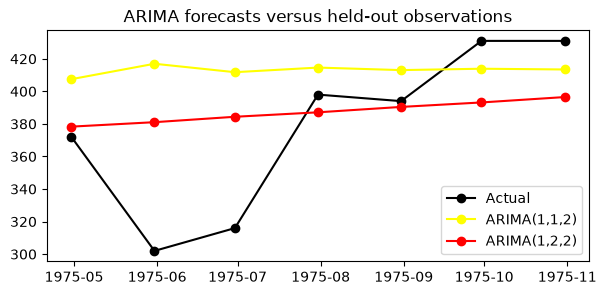

In [37]:
# Compare the two differenced-model predictions to the test observations.
fig = plt.figure(figsize=(7, 3))
plt.plot(test_crime, label='Actual', color='black', marker='o')
plt.plot(arima1_preds, label='ARIMA(1,1,2)', color='yellow', marker='o')
plt.plot(arima2_preds, label='ARIMA(1,2,2)', color='red', marker='o')
plt.title('ARIMA forecasts versus held-out observations')
plt.legend()
plt.show()

## 8. Time-series regression with leakage-free lagged predictors

Use the same 3-fold `TimeSeriesSplit` with seven-month test blocks and a default `KNeighborsRegressor`. The original example inadvertently included **`Diff1[t] = y[t] - y[t-1]`**, which directly reveals the target `y[t]`; it also included full-series fitted values (`ES`) and imputed before cross-validation. These invalidate the reported holdout errors.

Here predictors are restricted to **lag 7**, **lag 12**, and a change observed at **lag 7**. All three are already known at the beginning of each seven-month test block, so each fold can be evaluated as a genuine seven-step forecast without using its held-out targets. The corrected errors will differ from the old, leaky results.

In [38]:
# Keep the original expanding/rolling chronological validation configuration.
from sklearn.model_selection import TimeSeriesSplit

ts_cv = TimeSeriesSplit(n_splits=3, max_train_size=111, test_size=7)

In [39]:
# Inspect the source series and any fitted series retained for plotting.
crime.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 118 entries, 1966-01-31 to 1975-10-31
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   f03_observed_value  118 non-null    int64  
 1   ES                  118 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 2.8 KB


In [40]:
# Compute first differences to illustrate month-to-month changes.
# The contemporaneous Diff1 column is NOT used as a regression predictor.
crime['Diff1'] = crime['f03_observed_value'].diff()
display(crime[['f03_observed_value', 'Diff1']].head(7))

,f03_observed_value,Diff1
year_month,,
1966-01-31,41,NaN
1966-02-28,39,-2.0
1966-03-31,50,11.0
1966-04-30,40,-10.0
1966-05-31,43,3.0
1966-06-30,38,-5.0
1966-07-31,44,6.0


In [41]:
# Only historical observations available at least seven months earlier
# are admissible for the seven-month forecast blocks.
crime['lag_7'] = crime['f03_observed_value'].shift(7)
crime['lag_12'] = crime['f03_observed_value'].shift(12)
crime['prior_change_7'] = crime['Diff1'].shift(7)

regression_data = crime[
    ['lag_7', 'lag_12', 'prior_change_7', 'f03_observed_value']
].dropna()
X = regression_data[['lag_7', 'lag_12', 'prior_change_7']].copy()
y = regression_data['f03_observed_value'].copy()
print('Regression samples:', len(X), 'Predictors:', X.columns.tolist())

Regression samples: 106 Predictors: ['lag_7', 'lag_12', 'prior_change_7']


In [42]:
# Evaluate the original KNN regressor using chronological folds only.
# No imputation or full-series fitted predictions enter this model.
from sklearn.model_selection import cross_validate
from sklearn.neighbors import KNeighborsRegressor

scores = cross_validate(
    KNeighborsRegressor(), X, y, cv=ts_cv,
    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error']
)
mae_scores = -scores['test_neg_mean_absolute_error']
rmse_scores = -scores['test_neg_root_mean_squared_error']
print(
    f'Mean Absolute Error: {mae_scores.mean():.3f} +/- {mae_scores.std():.3f}\n'
    f'Root Mean Squared Error: {rmse_scores.mean():.3f} +/- {rmse_scores.std():.3f}'
)

Mean Absolute Error: 65.895 +/- 39.126
Root Mean Squared Error: 76.728 +/- 39.371
